# Model Selection and Hyperparameter Tuning — INSTRUCTOR SOLUTION

**Use scikit-learn as much as possible!**

**How to use this notebook.** Each coding part is answered in five beats: **Approach** → **code** (complete and
executed) → **What the code does** → **Expected output** → **Common mistakes**. Everything else is the student
notebook, unchanged.

**Conventions.** One shared `KFold(10, shuffle=True, random_state=5544)` for every Ames candidate (5 folds for
the larger Loans data), `scoring="neg_root_mean_squared_error"` (negate to get RMSE), preprocessing in a
`ColumnTransformer` inside a `Pipeline` (median imputer and scaler for numeric columns, one-hot encoder with
`handle_unknown="ignore"` for categoricals), grid-search parameters named `<step>__<parameter>`. Topic 10.1
builds exactly these pieces on the same data; its `preprocessing` and `cv_rmse` helpers are reused here.

Students will get different numbers with different folds, feature sets and grids; the *shape* of each answer is
what to look for.

In [1]:
import pandas as pd
import numpy as np

## Ames Housing Data

As usual, we'll try to predict SalePrice using a mix of quantitative and categorical features. See the [data documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) for all the variables that are available in the data set. We'll try to come up with a model that minimizes test error, measured by root mean square error (RMSE).

In [2]:
df_ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")
df_ames

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,2926,923275080,80,RL,37.0,7937,Pave,NaN,IR1,Lvl,...,0,NaN,GdPrv,NaN,0,3,2006,WD,Normal,142500
2926,2927,923276100,20,RL,NaN,8885,Pave,NaN,IR1,Low,...,0,NaN,MnPrv,NaN,0,6,2006,WD,Normal,131000
2927,2928,923400125,85,RL,62.0,10441,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,Shed,700,7,2006,WD,Normal,132000
2928,2929,924100070,20,RL,77.0,10010,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,170000


1\. Recall that in a previous notebook we fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. But what about other sets of features?

Specify 5 sets of features to investigate. These sets could be subsets of the variables above, but you should also include other variables from the data set. The choice is up to you, but try to guess which sets might lead to good models based on your intuition and what we have already seen for this data set.

For each set of features, fit a 10-nearest neighbors regression model and estimate its test error (RMSE) using cross-validation. You can write a loop to iterate over the sets of features similar to what was done in the Model Selection section of the pre-class notebook.

Report your lowest RMSE and the corresponding features.

### Solution 1 — five feature sets, 10-NN, cross-validated RMSE

**Approach.** Model selection as a loop: a dictionary of candidate feature sets (numeric and categorical
columns listed separately so the preprocessing can treat them differently), the *same* 10-nearest-neighbor
pipeline and the *same* ten folds for each, and a table of the cross-validated RMSEs. The sets start from the
previous notebook's five features and add the columns that the Ames exploration in PA 9.2 pointed at: overall
quality (the strongest single predictor), year built, basement size, garage capacity, and the quality
categoricals.

In [3]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV

y_ames = df_ames["SalePrice"]
folds = KFold(n_splits=10, shuffle=True, random_state=5544)        # the same 10 folds for every candidate

def preprocessing(numeric, categorical=(), scale=True):
    """Median-impute (+ scale) the numeric columns; one-hot encode the categorical ones."""
    steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scale", StandardScaler()))
    transformers = [("num", Pipeline(steps), list(numeric))]
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), list(categorical)))
    return ColumnTransformer(transformers)

def cv_rmse(model, X, y, cv=folds):
    """Cross-validated test RMSE on the shared folds."""
    return -cross_val_score(model, X, y, cv=cv, scoring="neg_root_mean_squared_error").mean()

In [4]:
base = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]

feature_sets = {
    "A: the five from before (base 4 + Neighborhood)":          (base, ["Neighborhood"]),
    "B: living area + overall quality":                          (["Gr Liv Area", "Overall Qual"], []),
    "C: area, quality, year built + Neighborhood":               (["Gr Liv Area", "Overall Qual", "Year Built"], ["Neighborhood"]),
    "D: C + basement sq ft, garage cars":                        (["Gr Liv Area", "Overall Qual", "Year Built", "Total Bsmt SF", "Garage Cars"], ["Neighborhood"]),
    "E: D + lot area, full bath, rooms, fireplaces + Kitchen Qual, Exter Qual":
        (["Gr Liv Area", "Overall Qual", "Year Built", "Total Bsmt SF", "Garage Cars", "Lot Area", "Full Bath", "TotRms AbvGrd", "Fireplaces"],
         ["Neighborhood", "Kitchen Qual", "Exter Qual"]),
}

part1 = {}
for name, (numeric, categorical) in feature_sets.items():
    knn10 = Pipeline([("prep", preprocessing(numeric, categorical)), ("knn", KNeighborsRegressor(n_neighbors=10))])
    part1[name] = cv_rmse(knn10, df_ames[numeric + categorical], y_ames)

part1 = pd.Series(part1, name="CV test RMSE (10-NN)").sort_values().round(0).to_frame()
part1

,CV test RMSE (10-NN)
"E: D + lot area, full bath, rooms, fireplaces + Kitchen Qual, Exter Qual",28766.0
"D: C + basement sq ft, garage cars",29649.0
"C: area, quality, year built + Neighborhood",32640.0
B: living area + overall quality,36346.0
A: the five from before (base 4 + Neighborhood),38441.0


In [5]:
best_set = part1.index[0]
print("lowest RMSE:", int(part1.iloc[0, 0]), "with", best_set)
print("features:", feature_sets[best_set][0] + feature_sets[best_set][1])

lowest RMSE: 28766 with E: D + lot area, full bath, rooms, fireplaces + Kitchen Qual, Exter Qual
features: ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Total Bsmt SF', 'Garage Cars', 'Lot Area', 'Full Bath', 'TotRms AbvGrd', 'Fireplaces', 'Neighborhood', 'Kitchen Qual', 'Exter Qual']


**What the code does.** `preprocessing` builds the column transformer each set needs (imputer because
`Total Bsmt SF` and `Garage Cars` each have one missing value; scaler because KNN measures distance; one-hot
with `handle_unknown="ignore"` so a rare neighborhood in a validation fold does not break the fold).
`cv_rmse` scores a pipeline on the shared folds. The loop changes only the columns.

**Expected output (these folds).** A ≈ 38,400 · B ≈ 36,300 · C ≈ 32,600 · D ≈ 29,600 · **E ≈ 28,800** (lowest).
Two features — living area and overall quality — already beat the five from before; adding year, basement,
garage and the quality categoricals keeps helping, by smaller and smaller steps. Students' sets will differ;
the pattern to look for is "quality and neighborhood matter, bedroom/bath counts add little once area is in".

**Common mistakes.**
- Forgetting to scale (KNN distances are then dominated by `Lot Area` and `Gr Liv Area`), or scaling the
  one-hot columns too (harmless but pointless).
- Including columns with missing values without an imputer: `KNeighborsRegressor` raises on `NaN`.
- Different `cv` for different sets — the comparison is only fair on the same folds.
- Reporting the *training* RMSE of each set.

2\. Recall that in a previous notebook we fit a $k$-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Previously we used a loop to iterate and find the value of $k$ with the smallest test error (RMSE).

Now use grid search in scikit-learn to implement this process. Use the results to create a plot of test error versus $k$.

### Solution 2 — grid search over k

**Approach.** The five features from before in a pipeline whose KNN step has *no* k; `GridSearchCV` supplies it
from `param_grid`. The parameter name is `knn__n_neighbors` because the step is called `"knn"`. Then turn
`cv_results_` into a DataFrame and plot RMSE (negated `mean_test_score`) against k.

In [6]:
numeric5, categorical5 = feature_sets["A: the five from before (base 4 + Neighborhood)"]
X5 = df_ames[numeric5 + categorical5]

knn_pipe = Pipeline([("prep", preprocessing(numeric5, categorical5)), ("knn", KNeighborsRegressor())])

grid_k = GridSearchCV(knn_pipe, {"knn__n_neighbors": range(1, 31)},
                      cv=folds, scoring="neg_root_mean_squared_error")
grid_k.fit(X5, y_ames)

print("best k:", grid_k.best_params_, "   CV test RMSE:", round(-grid_k.best_score_))

best k: {'knn__n_neighbors': 3}    CV test RMSE: 38200


,param_knn__n_neighbors,CV test RMSE,std_test_score,rank_test_score
0,1,45657.0,3913.0,30
1,2,39900.0,3406.0,17
2,3,38200.0,2491.0,1
3,4,38600.0,2615.0,7
4,5,38493.0,2835.0,6
5,6,38632.0,3686.0,8
6,7,38397.0,3912.0,4
7,8,38233.0,3977.0,2
8,9,38358.0,4017.0,3
9,10,38441.0,4037.0,5


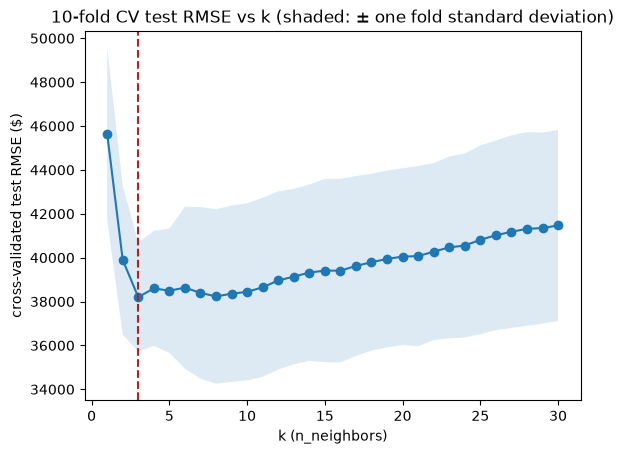

In [7]:
import matplotlib.pyplot as plt

results_k = pd.DataFrame(grid_k.cv_results_)
results_k["CV test RMSE"] = -results_k["mean_test_score"]

ax = results_k.plot(x="param_knn__n_neighbors", y="CV test RMSE", marker="o", legend=False)
ax.fill_between(results_k["param_knn__n_neighbors"],
                results_k["CV test RMSE"] - results_k["std_test_score"],
                results_k["CV test RMSE"] + results_k["std_test_score"], alpha=0.15)
ax.axvline(grid_k.best_params_["knn__n_neighbors"], color="firebrick", linestyle="--")
ax.set_xlabel("k (n_neighbors)"); ax.set_ylabel("cross-validated test RMSE ($)")
ax.set_title("10-fold CV test RMSE vs k (shaded: ± one fold standard deviation)");
results_k[["param_knn__n_neighbors", "CV test RMSE", "std_test_score", "rank_test_score"]].round(0).head(10)

**What the code does.** `grid_k.fit` fits 30 values × 10 folds = 300 pipelines, scores each on its held-out
fold, averages, and refits the best k on all 2,930 houses (`grid_k.best_estimator_`). `cv_results_` keeps every
mean (`mean_test_score`, negative RMSE), its spread over folds (`std_test_score`) and its rank.

**Expected output.** Best **k = 3** at about **38,200**, but the curve is nearly flat from k = 3 to k = 10
(38,200 – 38,650) and the fold standard deviation is 2,500 – 4,000, so the whole plateau is one answer; k = 1 is
clearly worse (≈ 45,700) and the error climbs slowly past k ≈ 12. This is the loop from PA 9.1 / 9.2 with the
search, the bookkeeping and the final refit done by scikit-learn.

**Common mistakes.**
- `param_grid={"n_neighbors": ...}` without the step prefix: `ValueError: Invalid parameter 'n_neighbors' for
  estimator Pipeline`. The name must be `knn__n_neighbors` (or `kneighborsregressor__n_neighbors` with
  `make_pipeline`).
- Plotting `mean_test_score` without negating, so the curve looks upside down.
- Reading `best_score_` as a positive RMSE (it is −38,200).

3\. $k$-nearest neighbors relies on distance and we know there are different distance metrics. Repeat the previous part and use grid search to iterate over both (1) `n_neighbors` and (2) `metric`, which can be `"euclidean"` or `"manhattan"` (see the the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)). Compare the results to the previous part. (Hint: recall the note in the pre-class notebook about grid search conventions for refering to steps in the pipeline.)

### Solution 3 — grid over k and the distance metric

**Approach.** Add a second key to the grid, `knn__metric`, with the two metrics. The grid is now 30 × 2 = 60
combinations × 10 folds = 600 fits. Pivot the results to one column per metric and plot both curves.

In [8]:
grid_km = GridSearchCV(knn_pipe,
                       {"knn__n_neighbors": range(1, 31), "knn__metric": ["euclidean", "manhattan"]},
                       cv=folds, scoring="neg_root_mean_squared_error")
grid_km.fit(X5, y_ames)

print("combinations:", len(grid_km.cv_results_["params"]), "  fits:", 10 * len(grid_km.cv_results_["params"]))
print("best:", grid_km.best_params_, "   CV test RMSE:", round(-grid_km.best_score_))

combinations: 60   fits: 600
best: {'knn__metric': 'manhattan', 'knn__n_neighbors': 5}    CV test RMSE: 37451


,best k,CV test RMSE
param_knn__metric,,
euclidean,3,38200.0
manhattan,5,37451.0


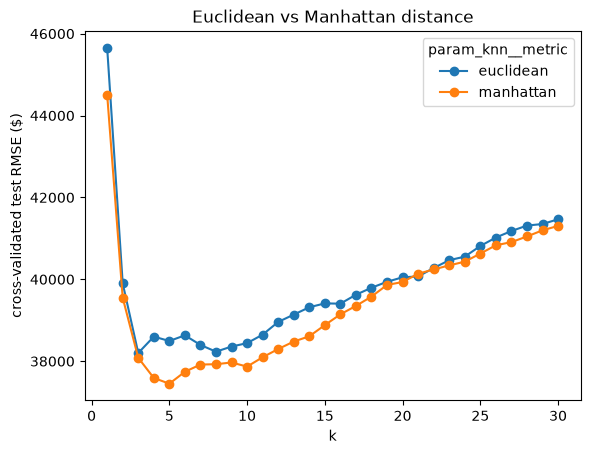

In [9]:
results_km = pd.DataFrame(grid_km.cv_results_)
results_km["CV test RMSE"] = -results_km["mean_test_score"]
wide = results_km.pivot(index="param_knn__n_neighbors", columns="param_knn__metric", values="CV test RMSE")

ax = wide.plot(marker="o"); ax.set_xlabel("k"); ax.set_ylabel("cross-validated test RMSE ($)")
ax.set_title("Euclidean vs Manhattan distance")
best_by_metric = pd.DataFrame({"best k": wide.idxmin(), "CV test RMSE": wide.min().round(0)})
best_by_metric

**What the code does.** Same search with every (k, metric) pair; `pivot` lays the two metrics side by side so
the two curves can be compared at every k; `idxmin` / `min` pick each metric's best k.

**Expected output.** **Manhattan, k = 5, about 37,450**, versus Euclidean's best of 38,200 at k = 3: Manhattan is
a little better at every small k and its curve bottoms out at a slightly larger k. The gap (≈ 750 dollars) is
real but small compared with the fold spread (≈ 3,000), so "Manhattan helps a bit here" is the right strength
of claim. Why it might: with one-hot neighborhood columns and scaled counts, Manhattan distance adds the
feature-by-feature differences instead of squaring them, so one unusual feature does not dominate the distance.

**Common mistakes.**
- Writing `"metric": [...]` without the `knn__` prefix (same error as part 2).
- Comparing the best of each metric at *different* k and concluding the metric did everything.
- Forgetting that the grid multiplies: 600 fits is fine here, but adding `weights` and `p` can take a while.

4\. Combine elements of the previous parts and fit what you think will be the best $k$-nearest neighbors model. Specify which features you are using, the value of $k$, and the distance metric. Estimate the test error. (In 2-3 you used the specified set of features. Now you can combine elements of 2-3 with the features you chose in part 1, or other sets of features, as well as investigating other parameter choices.)

Note: Look at the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html) for a full list of parameters. You might consider tuning `n_neighbors`, `metric` (or `p`), and/or `weights`. You could also try other elements like scaling too.

### Solution 4 — the best KNN model we can find

**Approach.** Combine the pieces: the best feature set from part 1 (set E) and the richer 12-numeric set from
PA 9.2, each with a grid over `n_neighbors`, `metric` and `weights` (`"distance"` weights nearer neighbors
more). Scaling stays in the pipeline. The grid is kept modest (9 × 2 × 2 = 36 combinations × 10 folds = 360
fits per feature set) so it runs in seconds.

In [10]:
twelve = ["Gr Liv Area", "Overall Qual", "Year Built", "Year Remod/Add", "Total Bsmt SF", "Garage Cars",
          "Lot Area", "Fireplaces", "Bedroom AbvGr", "Full Bath", "Half Bath", "TotRms AbvGrd"]
candidates = {
    "set E (9 numeric + Neighborhood, Kitchen Qual, Exter Qual)": feature_sets["E: D + lot area, full bath, rooms, fireplaces + Kitchen Qual, Exter Qual"],
    "12 numeric + Neighborhood":                                 (twelve, ["Neighborhood"]),
    "12 numeric + Neighborhood, Kitchen Qual, Exter Qual":       (twelve, ["Neighborhood", "Kitchen Qual", "Exter Qual"]),
}
knn_grid = {"knn__n_neighbors": [3, 4, 5, 6, 8, 10, 12, 15, 20],
            "knn__metric": ["euclidean", "manhattan"],
            "knn__weights": ["uniform", "distance"]}

searches = {}
for name, (numeric, categorical) in candidates.items():
    pipe = Pipeline([("prep", preprocessing(numeric, categorical)), ("knn", KNeighborsRegressor())])
    search = GridSearchCV(pipe, knn_grid, cv=folds, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(df_ames[numeric + categorical], y_ames)
    searches[name] = search
    print(f"{name:58s} best {search.best_params_}   CV test RMSE {-search.best_score_:,.0f}")

set E (9 numeric + Neighborhood, Kitchen Qual, Exter Qual) best {'knn__metric': 'manhattan', 'knn__n_neighbors': 4, 'knn__weights': 'distance'}   CV test RMSE 27,670


12 numeric + Neighborhood                                  best {'knn__metric': 'manhattan', 'knn__n_neighbors': 8, 'knn__weights': 'distance'}   CV test RMSE 27,322


12 numeric + Neighborhood, Kitchen Qual, Exter Qual        best {'knn__metric': 'manhattan', 'knn__n_neighbors': 5, 'knn__weights': 'distance'}   CV test RMSE 27,386


In [11]:
best_name = min(searches, key=lambda n: -searches[n].best_score_)
best_knn_search = searches[best_name]
numeric_best, categorical_best = candidates[best_name]
print("Best KNN model")
print("  features:", numeric_best + categorical_best)
print("  settings:", best_knn_search.best_params_)
print(f"  estimated test RMSE: {-best_knn_search.best_score_:,.0f}")

Best KNN model
  features: ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Year Remod/Add', 'Total Bsmt SF', 'Garage Cars', 'Lot Area', 'Fireplaces', 'Bedroom AbvGr', 'Full Bath', 'Half Bath', 'TotRms AbvGrd', 'Neighborhood']
  settings: {'knn__metric': 'manhattan', 'knn__n_neighbors': 8, 'knn__weights': 'distance'}
  estimated test RMSE: 27,322


**What the code does.** One grid search per candidate feature set, all on the shared folds; `n_jobs=-1` runs
the fits in parallel. The winner is the (feature set, settings) pair with the smallest mean validation RMSE.

**Expected output.** All three feature sets land between about **27,000 and 27,700** (set E: Manhattan, k = 4,
distance ≈ 27,670; 12 numeric + Neighborhood: Manhattan, k = 8, distance ≈ 27,320; with the two quality
categoricals added, about the same). The winning settings share **`weights="distance"`**, which helps by
roughly 1,000 – 2,000 dollars on every set, a small-to-middling k (4 – 10), and Manhattan distance by a hair.
Compared with part 1's 10-NN on set E (28,766), tuning buys about a thousand dollars; compared with part 2's
model (38,200), the features bought ten thousand. **Features first, then tuning** is the lesson.

**Common mistakes.**
- Tuning k on the five old features and then switching features without re-tuning.
- Leaving out `weights`, the setting that helped most here.
- Reading the best of 100+ combinations as an unbiased test error: it is slightly optimistic. A sealed test set
  (or nested CV) would confirm it; for a class competition, the shared-folds CV number is the agreed currency.
- Running a huge grid on 2,930 rows with 10 folds and `n_jobs=1`: fine, just slow. Start with coarse grids.

5\. Now fit a linear regression model using the same features that you used in the previous part. Estimate the test error. How does the test error for linear regression compare to the kNN model?


### Solution 5 — linear regression on the same features

**Approach.** Same features, same preprocessing, same folds; swap the KNN step for `LinearRegression()`, which
has nothing to tune.

In [12]:
linear_pipe = Pipeline([("prep", preprocessing(numeric_best, categorical_best)), ("lm", LinearRegression())])
linear_rmse = cv_rmse(linear_pipe, df_ames[numeric_best + categorical_best], y_ames)

pd.Series({"best KNN (tuned)": -best_knn_search.best_score_, "linear regression": linear_rmse},
          name="CV test RMSE").round(0).to_frame()

,CV test RMSE
best KNN (tuned),27322.0
linear regression,32601.0


**What the code does.** One `cross_val_score` on the same ten folds; the only difference from the KNN pipeline
is the final step.

**Expected output.** Linear regression at about **30,900 – 32,600** (depending on which feature set won part 4)
versus the tuned KNN's **≈ 27,000 – 27,700**: KNN wins by three to five thousand dollars on these features. The line is held back by relationships it cannot
bend to (price rises faster than linearly with area and quality; PA 9.2's degree-2 polynomial on twelve
numerics reached ≈ 26,200, which would beat the KNN here). KNN is a local average, so it follows that curvature
without being told — at the cost of interpretability and of needing scaling and a tuned k.

**Common mistakes.** Comparing the two models on different feature sets or different folds; leaving the scaler
out for the linear model (harmless for its RMSE, but the pipeline should stay identical so only the model
changes); concluding "KNN is always better" — the ranking is for these features, these folds and this metric.

## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

Note: when you are consider features to include, you might want to consider transformations of the variables.

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [13]:
df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

df

,Unnamed: 0,emp_title,emp_length,state,homeownership,annual_income,verified_income,debt_to_income,annual_income_joint,verification_income_joint,...,sub_grade,issue_month,loan_status,initial_listing_status,disbursement_method,balance,paid_total,paid_principal,paid_interest,paid_late_fees
0,1,global config engineer,3.0,NJ,MORTGAGE,90000.0,Verified,18.01,NaN,NaN,...,C3,Mar-2018,Current,whole,Cash,27015.86,1999.33,984.14,1015.19,0.0
1,2,warehouse office clerk,10.0,HI,RENT,40000.0,Not Verified,5.04,NaN,NaN,...,C1,Feb-2018,Current,whole,Cash,4651.37,499.12,348.63,150.49,0.0
2,3,assembly,3.0,WI,RENT,40000.0,Source Verified,21.15,NaN,NaN,...,D1,Feb-2018,Current,fractional,Cash,1824.63,281.80,175.37,106.43,0.0
3,4,customer service,1.0,PA,RENT,30000.0,Not Verified,10.16,NaN,NaN,...,A3,Jan-2018,Current,whole,Cash,18853.26,3312.89,2746.74,566.15,0.0
4,5,security supervisor,10.0,CA,RENT,35000.0,Verified,57.96,57000.0,Verified,...,C3,Mar-2018,Current,whole,Cash,21430.15,2324.65,1569.85,754.80,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,owner,10.0,TX,RENT,108000.0,Source Verified,22.28,NaN,NaN,...,A4,Jan-2018,Current,whole,Cash,21586.34,2969.80,2413.66,556.14,0.0
9996,9997,director,8.0,PA,MORTGAGE,121000.0,Verified,32.38,NaN,NaN,...,D3,Feb-2018,Current,whole,Cash,9147.44,1456.31,852.56,603.75,0.0
9997,9998,toolmaker,10.0,CT,MORTGAGE,67000.0,Verified,45.26,107000.0,Source Verified,...,E2,Feb-2018,Current,fractional,Cash,27617.65,4620.80,2382.35,2238.45,0.0
9998,9999,manager,1.0,WI,MORTGAGE,80000.0,Source Verified,11.99,NaN,NaN,...,A1,Feb-2018,Current,whole,Cash,21518.12,2873.31,2481.88,391.43,0.0


### Solution — the Loans competition

**Approach.** Explore first: size, missingness, the target's distribution, what each column *is* and **when it
is known**. That last question matters more here than any grid search: several columns in this file describe
the loan *after* it was priced and issued (`grade`, `sub_grade`, `installment`, `balance`, `paid_*`,
`loan_status`), and `sub_grade` is literally Lending Club's pricing tier — the interest rate is a function of
it. A model with `sub_grade` predicts the rate almost perfectly and teaches nothing about *who* gets a high
rate. So the competition is run twice: with **application-time features** (what the lender knew about the
borrower when setting the rate) as the real contest, and with the grade columns afterwards to show the
circularity. Transformations (logs of skewed money amounts), a shared `KFold(5)`, pipelines throughout, and
`GridSearchCV` for k, weights and tree depth.

In [14]:
print(df.shape)
print("interest_rate:", df["interest_rate"].describe().round(2).to_dict())
missing = df.isna().mean().sort_values(ascending=False)
print("columns with missing values (share):")
print(missing[missing > 0].round(3).to_string())

(10000, 56)
interest_rate: {'count': 10000.0, 'mean': 12.43, 'std': 5.0, 'min': 5.31, '25%': 9.43, '50%': 11.98, '75%': 15.05, 'max': 30.94}
columns with missing values (share):
verification_income_joint           0.854
annual_income_joint                 0.850
debt_to_income_joint                0.850
months_since_90d_late               0.772
months_since_last_delinq            0.566
months_since_last_credit_inquiry    0.127
emp_title                           0.083
emp_length                          0.082
num_accounts_120d_past_due          0.032
debt_to_income                      0.002


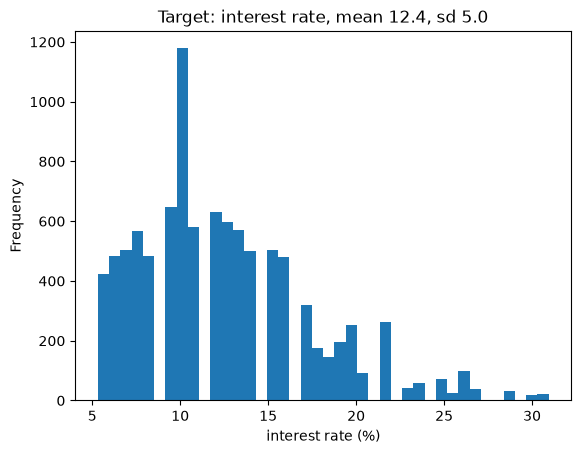

In [15]:
ax = df["interest_rate"].plot.hist(bins=40)
ax.set_xlabel("interest rate (%)"); ax.set_title("Target: interest rate, mean 12.4, sd 5.0");

In [16]:
numeric_corr = df.select_dtypes("number").corr()["interest_rate"].drop("interest_rate").sort_values()
print("strongest correlations with interest_rate:")
print(pd.concat([numeric_corr.head(6), numeric_corr.tail(6)]).round(2).to_string())

strongest correlations with interest_rate:
total_debit_limit                  -0.25
annual_income_joint                -0.17
num_mort_accounts                  -0.14
total_credit_limit                 -0.13
account_never_delinq_percent       -0.12
months_since_last_credit_inquiry   -0.10
inquiries_last_12m                  0.13
debt_to_income                      0.14
debt_to_income_joint                0.27
term                                0.36
paid_interest                       0.51
num_accounts_120d_past_due           NaN


In [17]:
for col in ["grade", "term", "verified_income", "homeownership", "application_type", "loan_purpose"]:
    print(f"\n--- {col} ---")
    print(df.groupby(col)["interest_rate"].agg(["mean", "count"]).round(2).to_string())


--- grade ---
        mean  count
grade              
A       6.74   2459
B      10.52   3037
C      14.18   2653
D      19.11   1446
E      25.10    335
F      29.40     58
G      30.80     12

--- term ---
       mean  count
term              
36    11.24   6970
60    15.15   3030

--- verified_income ---
                  mean  count
verified_income              
Not Verified     11.10   3594
Source Verified  12.52   4116
Verified         14.35   2290

--- homeownership ---
                mean  count
homeownership              
MORTGAGE       12.06   4789
OWN            12.31   1353
RENT           12.92   3858

--- application_type ---
                   mean  count
application_type              
individual        12.30   8505
joint             13.16   1495

--- loan_purpose ---
                     mean  count
loan_purpose                    
car                 12.04    131
credit_card         11.43   2249
debt_consolidation  13.01   5144
home_improvement    11.62    680
house  

What the exploration says: the rate runs from 5 % to 31 % with sd 5.0 (so a model must beat an RMSE of 5.0 to be
worth anything); 60-month loans carry about 4 points more than 36-month loans; verified income, renting and
joint applications go with higher rates; among numeric columns the strongest *honest* signals are weak
(`term`, `debt_to_income`, `inquiries_last_12m`, `accounts_opened_24m` positive; `total_debit_limit`,
`total_credit_limit`, `annual_income`, `num_mort_accounts` negative, all |r| ≤ 0.36). `grade` alone separates
means from 6.7 % (A) to 30.8 % (G): it *is* the rate. `paid_interest` correlates 0.51 with the rate because
interest paid is rate × balance — an outcome, not a predictor. The joint-income columns and `months_since_*`
are mostly missing and are left out; `emp_length` and `debt_to_income` have a few gaps the imputer fills.

**Round 1: application-time features.** Money amounts are right-skewed, so they enter as logs (a transformation
the task suggests); the pipeline does the rest.

In [18]:
df["log_income"]       = np.log1p(df["annual_income"])
df["log_loan_amount"]  = np.log(df["loan_amount"])
df["log_credit_limit"] = np.log1p(df["total_credit_limit"])
df["log_debit_limit"]  = np.log1p(df["total_debit_limit"])

app_numeric = ["term", "log_loan_amount", "log_income", "debt_to_income", "inquiries_last_12m", "accounts_opened_24m",
               "delinq_2y", "log_credit_limit", "log_debit_limit", "total_credit_utilized", "num_mort_accounts",
               "account_never_delinq_percent", "public_record_bankrupt", "emp_length", "earliest_credit_line",
               "total_credit_lines", "num_cc_carrying_balance"]
app_categorical = ["verified_income", "homeownership", "loan_purpose", "application_type"]

y_loans = df["interest_rate"]
folds5 = KFold(n_splits=5, shuffle=True, random_state=5544)
board = {}

def enter(name, model, columns):
    rmse = cv_rmse(model, df[columns], y_loans, cv=folds5)
    board[name] = rmse
    print(f"{name:55s} {rmse:6.3f}")
    return rmse

from sklearn.dummy import DummyRegressor
enter("predict the mean (benchmark: sd of the rate)", DummyRegressor(strategy="mean"), ["term"])
enter("linear: term + debt_to_income", Pipeline([("prep", preprocessing(["term", "debt_to_income"])), ("lm", LinearRegression())]), ["term", "debt_to_income"])
enter("linear: 17 application-time numerics", Pipeline([("prep", preprocessing(app_numeric)), ("lm", LinearRegression())]), app_numeric)
enter("linear: 17 numerics + 4 categoricals", Pipeline([("prep", preprocessing(app_numeric, app_categorical)), ("lm", LinearRegression())]), app_numeric + app_categorical);

predict the mean (benchmark: sd of the rate)             5.001
linear: term + debt_to_income                            4.630
linear: 17 application-time numerics                     4.191


linear: 17 numerics + 4 categoricals                     4.097


In [19]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor

# GridSearchCV over the polynomial degree of the numeric block (1 = plain linear, 2 = squares and products)
poly_pipe = Pipeline([
    ("prep", ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("poly", PolynomialFeatures(include_bias=False)), ("scale", StandardScaler())]), app_numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), app_categorical)])),
    ("lm", LinearRegression())])
grid_poly = GridSearchCV(poly_pipe, {"prep__num__poly__degree": [1, 2]}, cv=folds5, scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_poly.fit(df[app_numeric + app_categorical], y_loans)
board[f"linear: polynomial degree {grid_poly.best_params_['prep__num__poly__degree']} + 4 categoricals"] = -grid_poly.best_score_
print("polynomial grid:", grid_poly.best_params_, round(-grid_poly.best_score_, 3))

# GridSearchCV over k and weights for KNN
knn_loans = Pipeline([("prep", preprocessing(app_numeric, app_categorical)), ("knn", KNeighborsRegressor())])
grid_knn = GridSearchCV(knn_loans, {"knn__n_neighbors": [5, 10, 20, 40, 80, 160], "knn__weights": ["uniform", "distance"]},
                        cv=folds5, scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_knn.fit(df[app_numeric + app_categorical], y_loans)
board[f"KNN {grid_knn.best_params_}"] = -grid_knn.best_score_
print("KNN grid:", grid_knn.best_params_, round(-grid_knn.best_score_, 3))

# GridSearchCV over depth and leaf size for a tree (no scaling needed)
tree_loans = Pipeline([("prep", preprocessing(app_numeric, app_categorical, scale=False)), ("tree", DecisionTreeRegressor(random_state=5544))])
grid_tree = GridSearchCV(tree_loans, {"tree__max_depth": [3, 4, 5, 6, 8, 10, None], "tree__min_samples_leaf": [1, 10, 50]},
                         cv=folds5, scoring="neg_root_mean_squared_error", n_jobs=-1)
grid_tree.fit(df[app_numeric + app_categorical], y_loans)
board[f"tree {grid_tree.best_params_}"] = -grid_tree.best_score_
print("tree grid:", grid_tree.best_params_, round(-grid_tree.best_score_, 3))

polynomial grid: {'prep__num__poly__degree': 2} 3.932


KNN grid: {'knn__n_neighbors': 40, 'knn__weights': 'distance'} 4.182


tree grid: {'tree__max_depth': None, 'tree__min_samples_leaf': 50} 4.268


In [20]:
leaderboard = pd.Series(board, name="CV test RMSE (percentage points)").sort_values().round(3).to_frame()
leaderboard

,CV test RMSE (percentage points)
linear: polynomial degree 2 + 4 categoricals,3.932
linear: 17 numerics + 4 categoricals,4.097
"KNN {'knn__n_neighbors': 40, 'knn__weights': 'distance'}",4.182
linear: 17 application-time numerics,4.191
"tree {'tree__max_depth': None, 'tree__min_samples_leaf': 50}",4.268
linear: term + debt_to_income,4.630
predict the mean (benchmark: sd of the rate),5.001


**Round 2: the grade columns.** Same machinery, three more candidates — to see the circularity, not to win.

In [21]:
circular = {}
circular["grade only (7 dummies)"]      = cv_rmse(Pipeline([("prep", preprocessing([], ["grade"])), ("lm", LinearRegression())]), df[["grade"]], y_loans, cv=folds5)
circular["sub_grade only (32 dummies)"] = cv_rmse(Pipeline([("prep", preprocessing([], ["sub_grade"])), ("lm", LinearRegression())]), df[["sub_grade"]], y_loans, cv=folds5)
circular["sub_grade + term"]            = cv_rmse(Pipeline([("prep", preprocessing(["term"], ["sub_grade"])), ("lm", LinearRegression())]), df[["sub_grade", "term"]], y_loans, cv=folds5)
pd.Series(circular, name="CV test RMSE").round(3).to_frame()

,CV test RMSE
grade only (7 dummies),1.108
sub_grade only (32 dummies),0.191
sub_grade + term,0.191


In [22]:
df.groupby("sub_grade")["interest_rate"].agg(["mean", "std", "count"]).round(2).head(8)

,mean,std,count
sub_grade,,,
A1,5.32,0.00,422
A2,6.08,0.01,480
A3,6.72,0.00,504
A4,7.35,0.00,568
A5,7.97,0.00,485
B1,9.44,0.00,647
B2,9.93,0.00,638
B3,10.42,0.00,540


**What the code does.** `enter` scores a pipeline on the shared five folds and records it; three `GridSearchCV`
calls tune the polynomial degree (the parameter name walks down the nesting: `prep__num__poly__degree`), k and
weights, and the tree's depth and minimum leaf size; the leaderboard sorts everything. Round 2 repeats the
scoring with the grade columns.

**Expected output (5 folds, `random_state=5544`).**

| candidate | CV test RMSE |
|---|---|
| predict the mean (sd of the rate) | 5.00 |
| linear: term + debt_to_income | ≈ 4.63 |
| linear: 17 application-time numerics (logged amounts) | ≈ 4.19 |
| linear: + 4 categoricals | ≈ 4.10 |
| KNN, k = 40, distance weights | ≈ 4.18 |
| tree, no depth limit, min 50 per leaf | ≈ 4.27 |
| **linear: degree-2 polynomial + 4 categoricals** | **≈ 3.93** |
| grade only | ≈ 1.11 |
| sub_grade only | **≈ 0.19** |

Reading it: with everything the lender could know about the *borrower*, the best honest model is a degree-2
linear model at about **3.9 percentage points** — only 20 % better than guessing the mean. Interest rates are
mostly *not* predictable from these borrower facts, because Lending Club's pricing uses information not in
these columns (credit scores are absent). `grade` alone gets 1.1 and `sub_grade` 0.19: within a sub-grade the
rate's standard deviation is about 0.005, so the sub-grade *is* the rate, assigned by the lender after it had
decided the price. A student who enters a sub_grade model wins the competition on RMSE and should be asked:
"what would you need to know to *use* this model on a new applicant?" — the sub-grade, which exists only after
the rate is set. The same goes for `installment` (which is computed from the rate) and `paid_interest`.

What students typically find: `term` is the single most useful honest column; verified income and renting raise
the rate; logs of income and limits do not help a linear model (it is a hair worse with them) but keep KNN's distances sensible; KNN needs a
large k (40 – 80) on 10,000 noisy rows; trees want a large `min_samples_leaf`; squares and products of the numerics
are the biggest honest improvement.

**Common mistakes.**
- Using `grade`, `sub_grade`, `installment`, `balance`, `paid_*` or `loan_status` and reporting a tiny RMSE as if
  it were a prediction; ask when each column becomes known.
- Including `emp_title` (4,741 distinct strings) in the one-hot encoder, or `state` without thinking (50 dummies
  for little signal).
- Not imputing (`emp_length`, `debt_to_income` have gaps) and hitting `NaN` errors, or dropping those rows and
  changing the data for some candidates but not others.
- Grid-searching without `n_jobs=-1` on 10,000 rows and giving up on the wait; or searching k = 1 … 100 one by
  one when a coarse grid (5, 10, 20, 40, 80, 160) locates the plateau.
- Forgetting the double-underscore path for a parameter nested inside the `ColumnTransformer`
  (`prep__num__poly__degree`).
- Mistaking these 10,000 *funded* loans for applications: there is no "declined" group in the data, so nothing
  here says who gets a loan at all.